# YOLOv8 Object Detection on VisDrone

## Dataset Preparation and Exploration

This notebook prepares the VisDrone2019-DET dataset for object detection using YOLOv8.

### Objectives
- Download and prepare the dataset.
- Inspect the dataset structure and class names.
- Verify image and annotation files.
- Analyze object class distribution.
- Visualize images with ground-truth bounding boxes.

**Model:** YOLOv8n  
**Task:** Object detection  
**Dataset:** VisDrone2019-DET

In [1]:
import random
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

import torch
import ultralytics
from ultralytics import settings
from ultralytics.data.utils import check_det_dataset

print("Libraries imported successfully.")
print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Libraries imported successfully.
Ultralytics version: 8.4.178
PyTorch version: 2.14.1+cu126
CUDA available: True


In [2]:
# Find the project root from the current notebook directory
current_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in [current_dir, *current_dir.parents]
        if (path / "notebooks").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the YOLOv8-VisDrone project folder. "
        "Open this notebook from your project."
    )

DATASETS_DIR = PROJECT_ROOT / "datasets"
RUNS_DIR = PROJECT_ROOT / "runs"

DATASETS_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

# Configure Ultralytics storage locations
settings.update({
    "datasets_dir": str(DATASETS_DIR),
    "runs_dir": str(RUNS_DIR),
})

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATASETS_DIR)
print("Training runs directory:", RUNS_DIR)

Project root: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone
Dataset directory: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets
Training runs directory: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs


In [3]:
data = check_det_dataset("VisDrone.yaml")

print("Dataset downloaded and prepared successfully.")
print("Dataset path:", data["path"])
print("Training images:", data["train"])
print("Validation images:", data["val"])
print("Test images:", data.get("test"))
print("Class names:", data["names"])


WARNING Dataset 'VisDrone.yaml' images not found, missing path 'C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\notebooks\datasets\VisDrone\images\val'
Unzipping C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\notebooks\datasets\VisDrone\VisDrone2019-DET-val.zip to C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\notebooks\datasets\VisDrone\VisDrone2019-DET-val...: 100% ━━━━━━━━━━━━ 1099/1099 1.2Kfiles/s 0.9s<0.0s
Unzipping C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\notebooks\datasets\VisDrone\VisDrone2019-DET-test-dev.zip to C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\notebooks\datasets\VisDrone\VisDrone2019-DET-test-dev...: 100% ━━━━━━━━━━━━ 3223/3223 976.2files/s 3.3s.1ss
Unzipping C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\notebooks\datasets\VisDrone\VisDrone2019-DET-train.zip to C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\notebooks\datasets\VisDrone\VisDrone2019-DET-train...: 100% ━━━━━━━━━━━━ 12945/12945 378.1files/s 34.2s.1sss
Converting train: ━━━━━━━━━━━━ 6471 87.0it/s 1:15s
Converting 

In [4]:
from pathlib import Path
import shutil

# Find the project folders
PROJECT_ROOT = Path.cwd().resolve().parent
DATASETS_DIR = PROJECT_ROOT / "datasets"

# Location where VisDrone was downloaded
SOURCE = PROJECT_ROOT / "notebooks" / "datasets" / "VisDrone"

# Correct destination
DESTINATION = DATASETS_DIR / "VisDrone"

# Move the dataset
if SOURCE.exists() and not DESTINATION.exists():
    shutil.move(str(SOURCE), str(DESTINATION))
    print("Dataset moved successfully!")

elif DESTINATION.exists():
    print("Dataset is already in the correct location.")

else:
    print("Dataset not found. Stop and tell me.")

print("Dataset location:", DESTINATION)

Dataset moved successfully!
Dataset location: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone


In [5]:
print("Dataset exists:", (PROJECT_ROOT / "datasets" / "VisDrone").exists())
print("Images folder exists:", (PROJECT_ROOT / "datasets" / "VisDrone" / "images").exists())
print("Labels folder exists:", (PROJECT_ROOT / "datasets" / "VisDrone" / "labels").exists())

Dataset exists: True
Images folder exists: True
Labels folder exists: True


In [6]:
from pathlib import Path
import yaml

DATASET_DIR = PROJECT_ROOT / "datasets" / "VisDrone"
YAML_PATH = DATASET_DIR / "VisDrone.yaml"

# Find the dataset configuration file
yaml_files = list(DATASET_DIR.rglob("*.yaml"))

print("Dataset directory:", DATASET_DIR)
print("YAML files found:", yaml_files)

Dataset directory: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone
YAML files found: []


In [7]:
import yaml

DATASET_DIR = PROJECT_ROOT / "datasets" / "VisDrone"
YAML_PATH = DATASET_DIR / "VisDrone.yaml"

dataset_config = {
    "path": str(DATASET_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "pedestrian",
        1: "people",
        2: "bicycle",
        3: "car",
        4: "van",
        5: "truck",
        6: "tricycle",
        7: "awning-tricycle",
        8: "bus",
        9: "motor",
    },
}

with open(YAML_PATH, "w", encoding="utf-8") as file:
    yaml.safe_dump(dataset_config, file, sort_keys=False)

print("Configuration created:", YAML_PATH)

Configuration created: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\VisDrone.yaml


In [8]:
for split in ["train", "val", "test"]:
    images = DATASET_DIR / "images" / split
    labels = DATASET_DIR / "labels" / split

    print(
        f"{split}: "
        f"images folder = {images.exists()}, "
        f"labels folder = {labels.exists()}"
    )

train: images folder = True, labels folder = True
val: images folder = True, labels folder = True
test: images folder = True, labels folder = True


In [9]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

for split in ["train", "val", "test"]:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    image_files = [
        f for f in image_dir.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    label_files = list(label_dir.glob("*.txt"))

    print(f"{split.upper()}:")
    print(f"  Images: {len(image_files)}")
    print(f"  Labels: {len(label_files)}")

TRAIN:
  Images: 6471
  Labels: 6471
VAL:
  Images: 548
  Labels: 548
TEST:
  Images: 1610
  Labels: 1610


In [10]:
from collections import Counter

NUM_CLASSES = 10
label_counts = Counter()
invalid_files = []
invalid_rows = []

for split in ["train", "val", "test"]:
    label_dir = DATASET_DIR / "labels" / split

    for label_file in label_dir.glob("*.txt"):
        try:
            with open(label_file, "r", encoding="utf-8") as file:
                lines = file.readlines()
        except Exception as error:
            invalid_files.append((str(label_file), str(error)))
            continue

        for line_number, line in enumerate(lines, start=1):
            line = line.strip()

            # Empty label files are allowed for images with no objects
            if not line:
                continue

            parts = line.split()

            if len(parts) != 5:
                invalid_rows.append(
                    (str(label_file), line_number, "Expected 5 values")
                )
                continue

            try:
                class_id = int(parts[0])
                x_center, y_center, width, height = map(float, parts[1:])
            except ValueError:
                invalid_rows.append(
                    (str(label_file), line_number, "Non-numeric value")
                )
                continue

            if not 0 <= class_id < NUM_CLASSES:
                invalid_rows.append(
                    (str(label_file), line_number, "Invalid class ID")
                )
                continue

            if not all(
                0 <= value <= 1
                for value in [x_center, y_center, width, height]
            ):
                invalid_rows.append(
                    (str(label_file), line_number, "Coordinates outside [0, 1]")
                )
                continue

            if width == 0 or height == 0:
                invalid_rows.append(
                    (str(label_file), line_number, "Zero-sized bounding box")
                )
                continue

            label_counts[class_id] += 1

print("Valid object annotations:", sum(label_counts.values()))
print("Invalid label files:", len(invalid_files))
print("Invalid annotation rows:", len(invalid_rows))
print("\nObjects per class:")

for class_id, name in {
    0: "pedestrian",
    1: "people",
    2: "bicycle",
    3: "car",
    4: "van",
    5: "truck",
    6: "tricycle",
    7: "awning-tricycle",
    8: "bus",
    9: "motor",
}.items():
    print(f"{class_id}: {name}: {label_counts[class_id]}")

Valid object annotations: 457065
Invalid label files: 0
Invalid annotation rows: 1

Objects per class:
0: pedestrian: 109187
1: people: 38560
2: bicycle: 13069
3: car: 187004
4: van: 32702
5: truck: 16284
6: tricycle: 6387
7: awning-tricycle: 4377
8: bus: 9117
9: motor: 40378


In [11]:
print("Invalid annotation details:")

for item in invalid_rows:
    print(item)

Invalid annotation details:
('C:\\Users\\USER\\Desktop\\ML\\ML\\YOLOv8-VisDrone\\datasets\\VisDrone\\labels\\train\\9999985_00000_d_0000020.txt', 11, 'Zero-sized bounding box')


In [12]:
bad_label = (
    DATASET_DIR
    / "labels"
    / "train"
    / "9999985_00000_d_0000020.txt"
)

with open(bad_label, "r", encoding="utf-8") as file:
    lines = file.readlines()

print("Line 11:", repr(lines[10]))
print("\nFull label file:")
for number, line in enumerate(lines, start=1):
    print(f"{number}: {line.rstrip()}")

Line 11: '3 0.437857 0.150476 0.002857 0.000000\n'

Full label file:
1: 4 0.440357 0.191905 0.006429 0.016190
2: 4 0.432143 0.187143 0.004286 0.012381
3: 4 0.507857 0.351905 0.012857 0.021905
4: 4 0.485357 0.246667 0.012143 0.026667
5: 4 0.450357 0.153810 0.003571 0.008571
6: 4 0.436429 0.171905 0.002857 0.006667
7: 4 0.455714 0.169048 0.004286 0.006667
8: 4 0.432500 0.167143 0.005000 0.006667
9: 4 0.433929 0.156667 0.003571 0.006667
10: 4 0.431786 0.136667 0.002143 0.004762
11: 3 0.437857 0.150476 0.002857 0.000000
12: 3 0.447500 0.147143 0.002143 0.000952
13: 3 0.448214 0.159524 0.002143 0.002857
14: 3 0.443214 0.146190 0.002143 0.002857
15: 3 0.435000 0.149524 0.002857 0.001905
16: 3 0.432500 0.141905 0.003571 0.003810
17: 3 0.454643 0.253810 0.005000 0.008571
18: 3 0.484643 0.305238 0.007857 0.010476
19: 3 0.492143 0.394286 0.010000 0.013333
20: 3 0.412500 0.183333 0.003571 0.006667
21: 3 0.457143 0.387619 0.010000 0.017143
22: 3 0.461071 0.469048 0.013571 0.027619
23: 3 0.442500 0

In [13]:
bad_label = (
    DATASET_DIR
    / "labels"
    / "train"
    / "9999985_00000_d_0000020.txt"
)

with open(bad_label, "r", encoding="utf-8") as file:
    lines = file.readlines()

# Remove only line 11 if it is the confirmed invalid annotation
target_line = "3 0.437857 0.150476 0.002857 0.000000"

matches = [
    i for i, line in enumerate(lines)
    if line.strip() == target_line
]

if len(matches) == 1:
    lines.pop(matches[0])

    with open(bad_label, "w", encoding="utf-8") as file:
        file.writelines(lines)

    print("Removed the single invalid annotation.")
else:
    print("Expected exactly one matching row; no changes made.")

Removed the single invalid annotation.


In [16]:
from collections import Counter

NUM_CLASSES = 10
label_counts = Counter()
invalid_files = []
invalid_rows = []

class_names = {
    0: "pedestrian",
    1: "people",
    2: "bicycle",
    3: "car",
    4: "van",
    5: "truck",
    6: "tricycle",
    7: "awning-tricycle",
    8: "bus",
    9: "motor",
}

for split in ["train", "val", "test"]:
    label_dir = DATASET_DIR / "labels" / split

    for label_file in label_dir.glob("*.txt"):
        try:
            with open(label_file, "r", encoding="utf-8") as file:
                lines = file.readlines()
        except Exception as error:
            invalid_files.append((str(label_file), str(error)))
            continue

        for line_number, line in enumerate(lines, start=1):
            parts = line.split()

            if not parts:
                continue

            if len(parts) != 5:
                invalid_rows.append(
                    (str(label_file), line_number, "Expected 5 values")
                )
                continue

            try:
                class_id = int(parts[0])
                x_center, y_center, width, height = map(float, parts[1:])
            except ValueError:
                invalid_rows.append(
                    (str(label_file), line_number, "Non-numeric value")
                )
                continue

            if not 0 <= class_id < NUM_CLASSES:
                invalid_rows.append(
                    (str(label_file), line_number, "Invalid class ID")
                )
                continue

            if not all(
                0 <= value <= 1
                for value in [x_center, y_center, width, height]
            ):
                invalid_rows.append(
                    (str(label_file), line_number, "Coordinates outside [0, 1]")
                )
                continue

            if width <= 0 or height <= 0:
                invalid_rows.append(
                    (str(label_file), line_number, "Zero or negative box size")
                )
                continue

            label_counts[class_id] += 1

print("VALIDATION SUMMARY")
print("-" * 35)
print("Valid object annotations:", sum(label_counts.values()))
print("Invalid label files:", len(invalid_files))
print("Invalid annotation rows:", len(invalid_rows))

print("\nOBJECTS PER CLASS")
for class_id, name in class_names.items():
    print(f"{class_id}: {name}: {label_counts[class_id]}")

if invalid_files:
    print("\nInvalid files:", invalid_files[:10])

if invalid_rows:
    print("\nInvalid rows:", invalid_rows[:10])

VALIDATION SUMMARY
-----------------------------------
Valid object annotations: 457065
Invalid label files: 0
Invalid annotation rows: 0

OBJECTS PER CLASS
0: pedestrian: 109187
1: people: 38560
2: bicycle: 13069
3: car: 187004
4: van: 32702
5: truck: 16284
6: tricycle: 6387
7: awning-tricycle: 4377
8: bus: 9117
9: motor: 40378


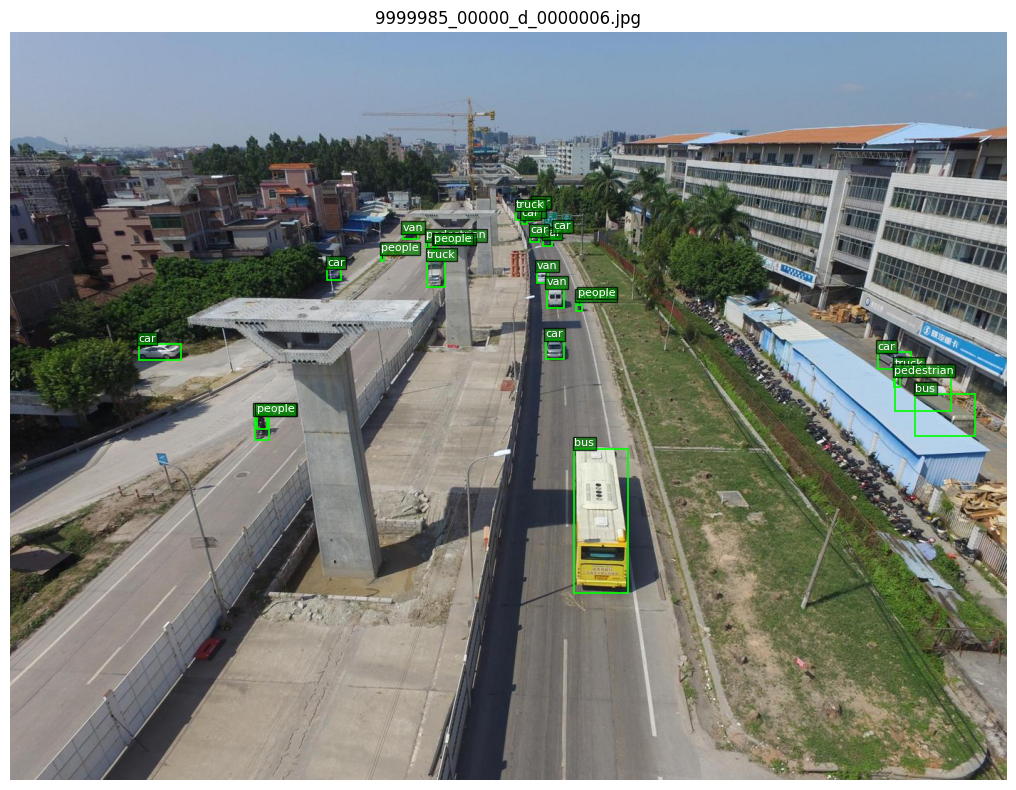

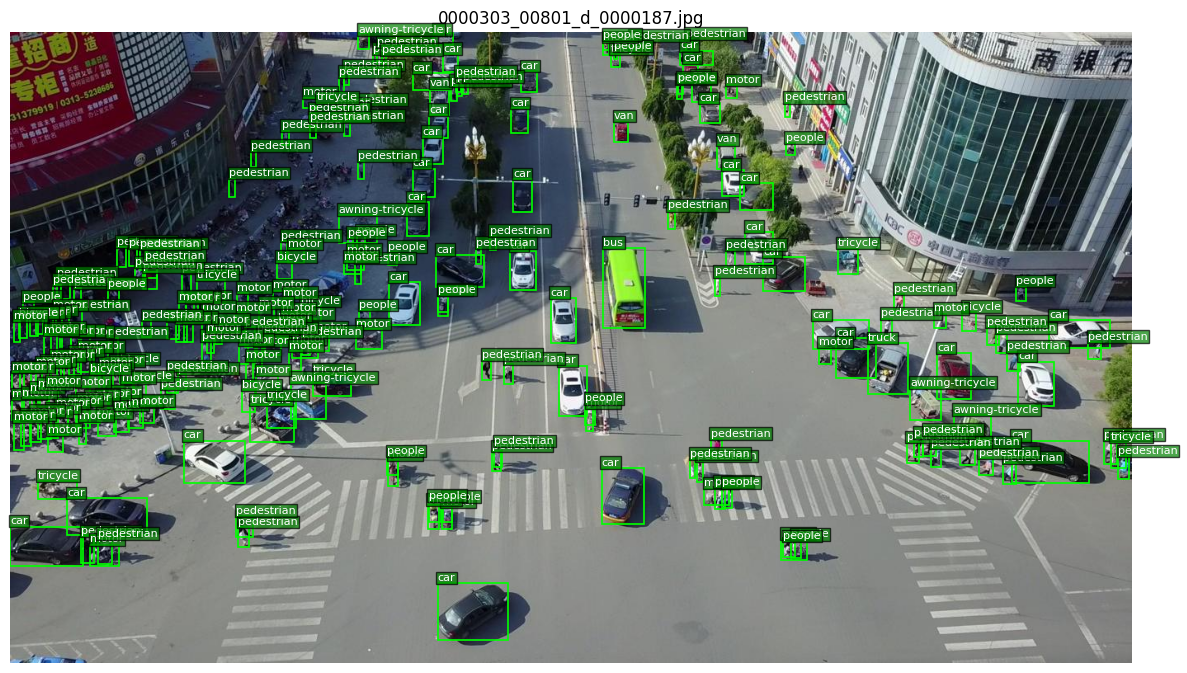

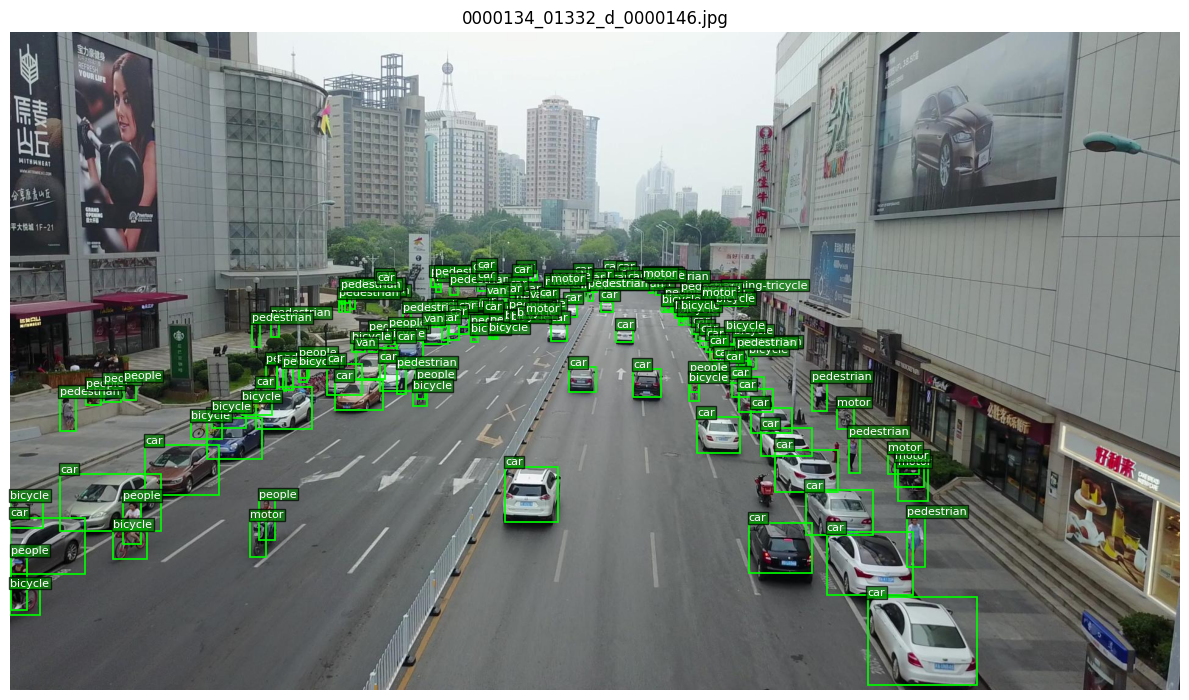

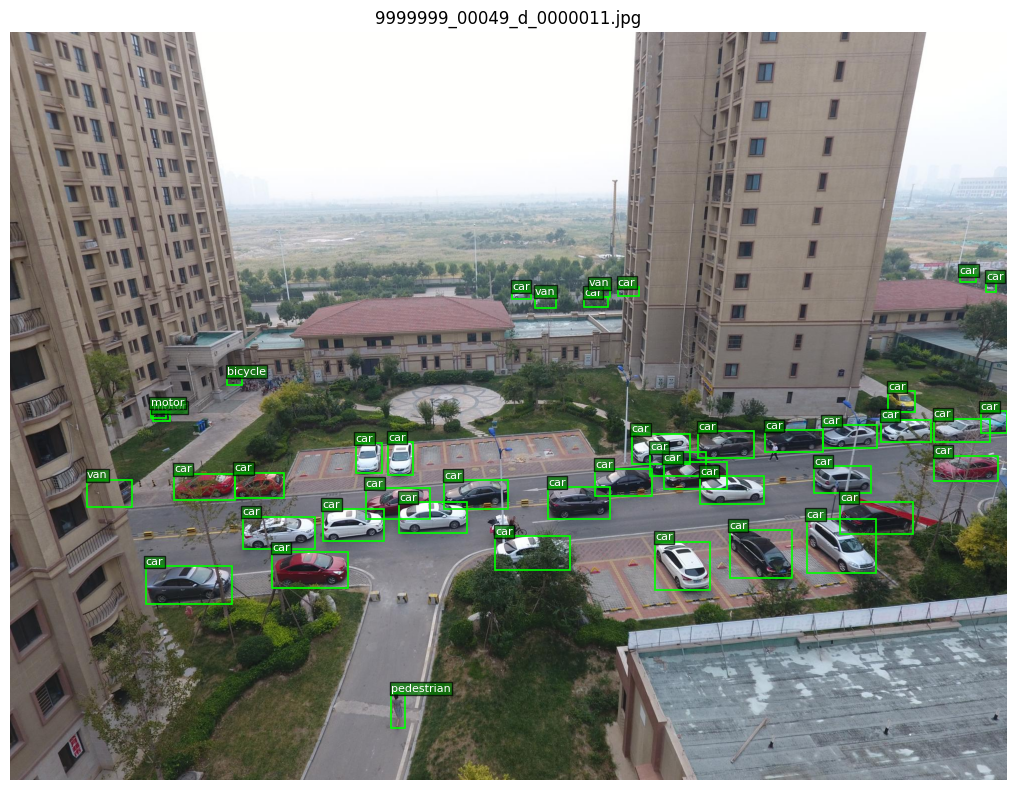

In [17]:
import random
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

IMAGE_DIR = DATASET_DIR / "images" / "train"
LABEL_DIR = DATASET_DIR / "labels" / "train"

image_files = list(IMAGE_DIR.glob("*.jpg"))

random.seed(42)
selected_images = random.sample(image_files, 4)

for image_path in selected_images:
    image = cv2.imread(str(image_path))

    if image is None:
        print("Could not read:", image_path.name)
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    label_path = LABEL_DIR / f"{image_path.stem}.txt"

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)
    ax.set_title(image_path.name)

    if label_path.exists():
        with open(label_path, "r", encoding="utf-8") as file:
            for line in file:
                parts = line.split()

                if len(parts) != 5:
                    continue

                class_id = int(parts[0])
                x_center, y_center, box_width, box_height = map(
                    float, parts[1:]
                )

                x1 = (x_center - box_width / 2) * width
                y1 = (y_center - box_height / 2) * height
                box_width_px = box_width * width
                box_height_px = box_height * height

                ax.add_patch(
                    Rectangle(
                        (x1, y1),
                        box_width_px,
                        box_height_px,
                        fill=False,
                        edgecolor="lime",
                        linewidth=1.2,
                    )
                )

                ax.text(
                    x1,
                    max(0, y1 - 3),
                    class_names[class_id],
                    color="white",
                    fontsize=8,
                    bbox=dict(facecolor="green", alpha=0.7, pad=1),
                )

    ax.axis("off")
    plt.tight_layout()
    plt.show()

In [18]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset(str(YAML_PATH))

print("Dataset path:", data["path"])
print("Training images:", data["train"])
print("Validation images:", data["val"])
print("Test images:", data.get("test"))
print("Classes:", data["names"])
print("Number of classes:", data["nc"])

Dataset path: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone
Training images: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\train
Validation images: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\val
Test images: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\test
Classes: {0: 'pedestrian', 1: 'people', 2: 'bicycle', 3: 'car', 4: 'van', 5: 'truck', 6: 'tricycle', 7: 'awning-tricycle', 8: 'bus', 9: 'motor'}
Number of classes: 10
